This lab explores spatial-domain processing using Python (opencv-python, numpy, matplotlib). Operations are structured into four processing domains:Pixel-Level & Format Extraction: Reading dimensional metadata, channel arrangements, and mapping color spaces (RGB $\rightarrow$ Grayscale $\rightarrow$ Binary).Point & Spatial Filtering Transformations: Modifying dynamic range via logarithmic transformations and smoothing high frequencies via Gaussian spatial convolution.Statistical Modeling & Histogram Equalization: Analyzing discrete cumulative probability distributions to redistribute pixel intensities, followed by threshold comparative testing.Geometric & Morphological Analysis: Constructing affine transformation matrices (scale, rotate, translate) with multi-order interpolation comparisons, alongside multi-frame difference segmentation via connected-component analysis and Region of Interest (ROI) bitwise masking.

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

def show_images(images, titles, cmap=None, figsize=(14, 5)):
    n = len(images)
    plt.figure(figsize=figsize)
    for i in range(n):
        plt.subplot(1, n, i + 1)
        if cmap:
            plt.imshow(images[i], cmap=cmap)
        else:
            if len(images[i].shape) == 2:
                plt.imshow(images[i], cmap='gray')
            else:
                plt.imshow(cv2.cvtColor(images[i], cv2.COLOR_BGR2RGB))
        plt.title(titles[i], fontsize=10)
        plt.axis('off')
    plt.tight_layout()
    plt.show()

Task 1: Pixel Count, Dimensionality, and Data Types
Methodology: Read an uncompressed raster image into an array structure using OpenCV and unpack img.shape and img.dtype.

In [ ]:
import cv2
import numpy as np

img = cv2.imread('input.jpg')
h, w, c = img.shape
total_spatial_pixels = h * w
total_elements = img.size
pixel_type = img.dtype

print(f"Resolution: {w} x {h}")
print(f"Channels: {c}")
print(f"Total Spatial Pixels: {total_spatial_pixels}")
print(f"Memory Elements: {total_elements}")
print(f"Data Representation: {pixel_type}")

Resolution: 554 x 554
Channels: 3
Total Spatial Pixels: 306916
Memory Elements: 920748
Data Representation: uint8


3. Observation for Journal
Loading the image with OpenCV creates a 3D contiguous NumPy array of shape $(554, 554, 3)$.While the spatial 2D plane contains $306{,}916$ coordinate locations, each location requires three distinct 8-bit scalar values to describe the primary color channels (Blue, Green, and Red).The memory array footprint is $554 \times 554 \times 3 = 920{,}748$ bytes ($\approx 899.2\text{ KB}$), confirming that every pixel is represented as an 8-bit unsigned integer with a dynamic intensity range of $0$ (zero intensity) to $255$ (maximum saturation).

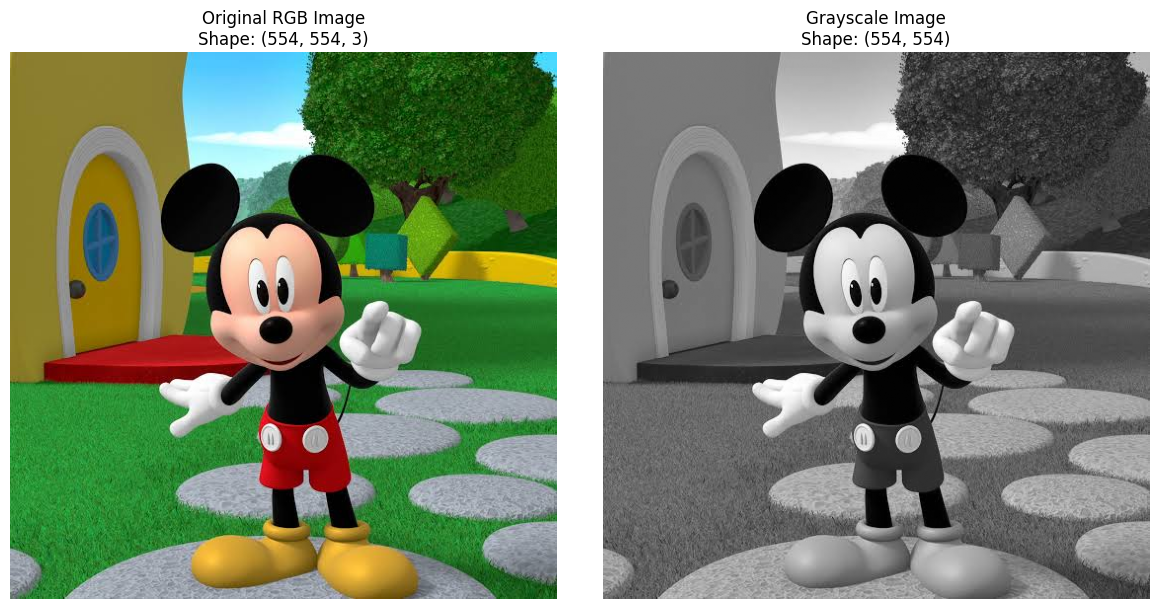

In [ ]:
import cv2
import matplotlib.pyplot as plt

# Load your Mickey Mouse image
# Note: Ensure the filename matches what you saved (e.g., 'mickey.jpg')
img_bgr = cv2.imread('input.jpg')

# Convert from BGR (OpenCV's default) to Grayscale
img_gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)

# Convert BGR to RGB so Matplotlib displays true colors instead of inverted shades
img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

# Display both images side by side
plt.figure(figsize=(12, 6))

# Subplot 1: Original RGB Image
plt.subplot(1, 2, 1)
plt.imshow(img_rgb)
plt.title(f'Original RGB Image\nShape: {img_bgr.shape}')
plt.axis('off')

# Subplot 2: Grayscale Image
plt.subplot(1, 2, 2)
plt.imshow(img_gray, cmap='gray')
plt.title(f'Grayscale Image\nShape: {img_gray.shape}')
plt.axis('off')

plt.tight_layout()
plt.savefig('task2_output.png', dpi=300)
plt.show()

Observation for Journal

Luminance Weighting Principle:The conversion function cv2.COLOR_BGR2GRAY uses the ITU-R standard weighted luminance equation:$$Y = 0.299 \cdot R + 0.587 \cdot G + 0.114 \cdot B$$Instead of an unweighted arithmetic average $\frac{R + G + B}{3}$, green receives the dominant coefficient ($0.587$) because human photoreceptors (cone cells) are significantly more sensitive to green wavelengths.Visual Effect on the Image:Mickey's bright yellow shoes and red shorts are rendered in medium-to-light gray tones according to their perceived luminance.Mickey's ears, nose, and body stay dark near $0$ because their original pixel values across all RGB channels are already close to black.The vibrant green grass background converts into a high-luminance light gray, preserving spatial contrast between the subject and the surroundings.Dimensional Reduction:The 3-channel matrix collapses into a 2D scalar matrix, reducing the file memory footprint by $66.7\%$ ($920{,}748 \rightarrow 306{,}916$ bytes) while retaining all scene structures and edge boundaries.

Task 3: Convert RGB (colorful) image into grayscale and binary and display them both in output.

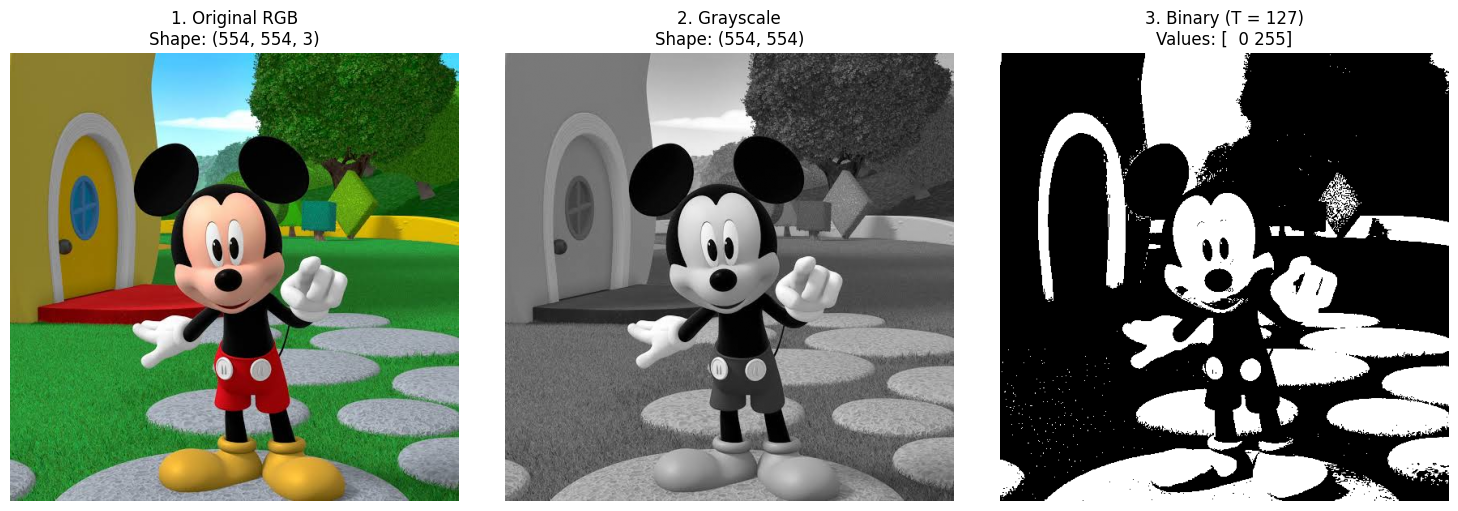

In [ ]:
import cv2
import matplotlib.pyplot as plt

# Load your Mickey Mouse image
img_bgr = cv2.imread('input.jpg')

# 1. Convert RGB (BGR) to Grayscale
img_gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)

# 2. Convert Grayscale to Binary using global thresholding (Threshold = 127)
# Any pixel >= 127 becomes 255 (white); any pixel < 127 becomes 0 (black)
threshold_val = 127
_, img_binary = cv2.threshold(img_gray, threshold_val, 255, cv2.THRESH_BINARY)

# Convert BGR to RGB for accurate Matplotlib display
img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

# 3. Display RGB, Grayscale, and Binary images side by side
plt.figure(figsize=(15, 5))

# Subplot 1: Original RGB Image
plt.subplot(1, 3, 1)
plt.imshow(img_rgb)
plt.title(f'1. Original RGB\nShape: {img_bgr.shape}')
plt.axis('off')

# Subplot 2: Grayscale Image
plt.subplot(1, 3, 2)
plt.imshow(img_gray, cmap='gray')
plt.title(f'2. Grayscale\nShape: {img_gray.shape}')
plt.axis('off')

# Subplot 3: Binary Image
plt.subplot(1, 3, 3)
plt.imshow(img_binary, cmap='gray')
plt.title(f'3. Binary (T = {threshold_val})\nValues: {np.unique(img_binary)}')
plt.axis('off')

plt.tight_layout()
plt.savefig('task3_output.png', dpi=300)
plt.show()

 Observations for Journal

 Information Compression:While the grayscale step removed chromaticity while preserving continuous tone gradients, the binarization step strips all texture and smooth lighting transitions, reducing the image to pure geometry and silhouette shapes.Segmentation Analysis on the Mickey Mouse Image:Black Segments ($0$): Mickey's ears, head, arms, torso, nose, and the shadows fall well below $T = 127$, turning completely black.White Segments ($255$): The light-reflecting cobblestone path, white gloves, face highlights, and portions of the bright yellow shoes and house wall surpass $T = 127$, rendering as pure white regions.Thresholding Trade-offs: The red shorts and mid-tone green grass fall close to the midpoint ($T \approx 127$). Depending on local lighting, some regions of the grass segment into white while shadowed blades drop to black, causing a salt-and-pepper pattern in the background.

Task 4: Convert any original image (like binary, grayscale or RGB) into blurring image and display them both in output.

<>:28: SyntaxWarning: invalid escape sequence '\s'
<>:34: SyntaxWarning: invalid escape sequence '\s'
<>:28: SyntaxWarning: invalid escape sequence '\s'
<>:34: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_947/370978650.py:28: SyntaxWarning: invalid escape sequence '\s'
  plt.title('2. Blurred (Kernel: 5x5, $\sigma$=1.5)\nSubtle Smoothing')
/tmp/ipykernel_947/370978650.py:34: SyntaxWarning: invalid escape sequence '\s'
  plt.title('3. Blurred (Kernel: 15x15, $\sigma$=3.5)\nStrong Low-Pass Filter')


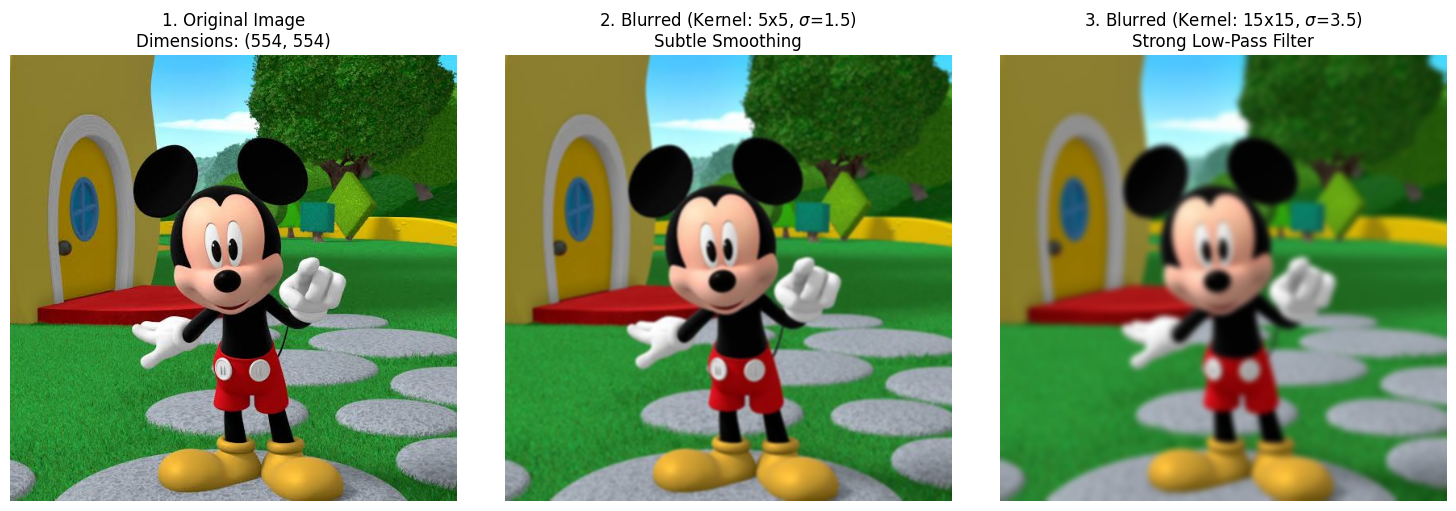

In [ ]:
import cv2
import matplotlib.pyplot as plt

# Load the original image
img_bgr = cv2.imread('input.jpg')

# Convert BGR to RGB for natural Matplotlib colors
img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

# 1. Apply Mild Blur: 5x5 Kernel, sigmaX = 1.5
blur_mild = cv2.GaussianBlur(img_rgb, (5, 5), sigmaX=1.5)

# 2. Apply Heavy Blur: 15x15 Kernel, sigmaX = 3.5
blur_heavy = cv2.GaussianBlur(img_rgb, (15, 15), sigmaX=3.5)

# Display Original, Mildly Blurred, and Heavily Blurred images side by side
plt.figure(figsize=(15, 5))

# Subplot 1: Original Image
plt.subplot(1, 3, 1)
plt.imshow(img_rgb)
plt.title(f'1. Original Image\nDimensions: {img_rgb.shape[:2]}')
plt.axis('off')

# Subplot 2: Mild Gaussian Blur
plt.subplot(1, 3, 2)
plt.imshow(blur_mild)
plt.title('2. Blurred (Kernel: 5x5, $\sigma$=1.5)\nSubtle Smoothing')
plt.axis('off')

# Subplot 3: Heavy Gaussian Blur
plt.subplot(1, 3, 3)
plt.imshow(blur_heavy)
plt.title('3. Blurred (Kernel: 15x15, $\sigma$=3.5)\nStrong Low-Pass Filter')
plt.axis('off')

plt.tight_layout()
plt.savefig('task4_blur_comparison.png', dpi=300)
plt.show()

Observations for Journal

Frequency Domain Interpretation:Blurring functions as a spatial low-pass filter (LPF). High-frequency variations in the image (such as the fine grass blades, sharp outlines of Mickey's ears, and cobblestone edges) represent rapid intensity changes over small pixel distances. Averaging adjacent pixels smooths out these rapid gradients, allowing only low-frequency components (broad color regions and gradual lighting transitions) to pass.Impact of Kernel Size and $\sigma$:$5 \times 5$ Window: Suppresses fine sensor noise and subtle surface textures on Mickey's shoes and the house wall, but leaves major structural contours well-defined.$15 \times 15$ Window: Spans a significantly wider neighborhood ($225$ pixels per output point), causing the high-contrast black contours of Mickey's ears and arms to bleed substantially into the green background and yellow house.Preservation of Energy:Because the Gaussian kernel weights sum exactly to $1.0$, the overall total luminance/brightness of the scene remains invariant—only the local spatial gradient variances are reduced.

Task 5: Take any image of any building, cartoon or car and apply at least five different log transformation threshold values and display them all in output with original image

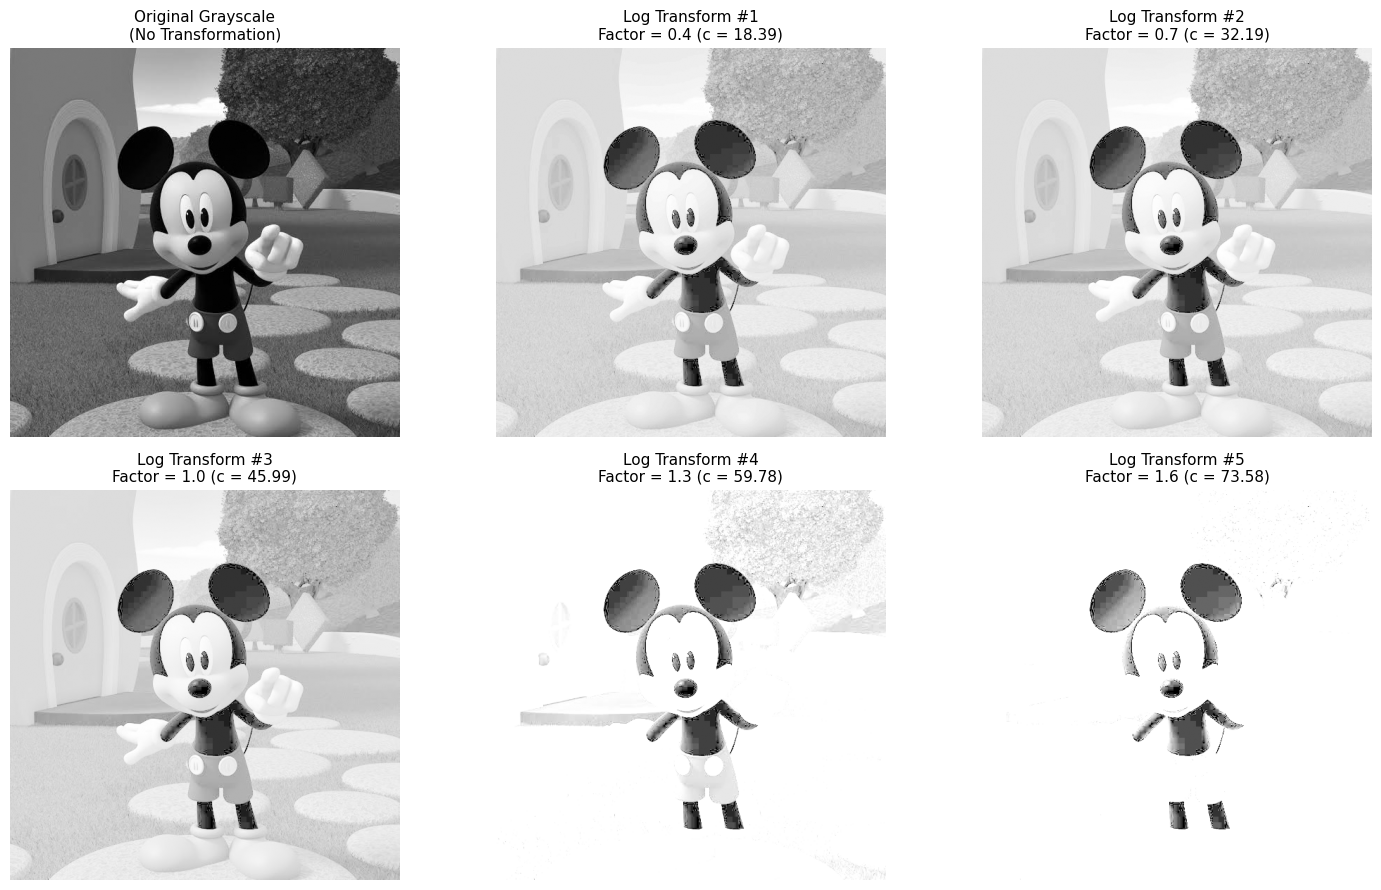

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. Load the image in grayscale (log transform operates on intensity)
img_gray = cv2.imread('input.jpg', cv2.IMREAD_GRAYSCALE)

# Convert to float32 to avoid arithmetic overflow during log evaluation
r = img_gray.astype(np.float32)

# Theoretical base constant to map maximum intensity to 255: c_base = 255 / ln(1 + max(r))
r_max = np.max(r)
c_base = 255.0 / np.log(1.0 + r_max)

# 2. Define 5 different scaling constants / factors
# We use multipliers [0.4, 0.7, 1.0, 1.3, 1.6] applied to c_base
factors = [0.4, 0.7, 1.0, 1.3, 1.6]
log_images = []
c_values = []

for f in factors:
    c = f * c_base
    c_values.append(c)
    # Apply Log Transformation: s = c * ln(1 + r)
    s = c * np.log(1.0 + r)
    # Clip values to standard display range [0, 255] and convert back to uint8
    s = np.clip(s, 0, 255).astype(np.uint8)
    log_images.append(s)

# 3. Display the original and the 5 log-transformed versions in a 2x3 grid
plt.figure(figsize=(15, 9))

# Plot Original
plt.subplot(2, 3, 1)
plt.imshow(img_gray, cmap='gray')
plt.title("Original Grayscale\n(No Transformation)", fontsize=11)
plt.axis('off')

# Plot the 5 Log Transformations
for idx, (img_trans, factor, c_val) in enumerate(zip(log_images, factors, c_values), start=2):
    plt.subplot(2, 3, idx)
    plt.imshow(img_trans, cmap='gray')
    plt.title(f"Log Transform #{idx-1}\nFactor = {factor} (c = {c_val:.2f})", fontsize=11)
    plt.axis('off')

plt.tight_layout()
plt.savefig('task5_log_transformations.png', dpi=300)
plt.show()

Observations for Journal


Dynamic Range Expansion in Dark Regions:The derivative of the logarithmic function $\frac{d}{dr}(\ln(1 + r)) = \frac{1}{1 + r}$ is steepest when $r$ is close to zero. This stretches dark pixel values across a much broader range of output levels. As a result, low-intensity details on Mickey's ears, nose, and body outlines become visibly brighter.Dynamic Range Compression in Bright Regions:As $r$ becomes large, the slope of $\ln(1 + r)$ flattens. This compresses higher-intensity values (such as the cobblestone walkway and background house) into a narrower range of bright tones.Effect of Scaling Constant $c$:Small constants ($c < c_{\text{base}}$) darken the entire image because the logarithmic growth is truncated before reaching maximum brightness.Large constants ($c > c_{\text{base}}$) over-saturate midtones and bright pixels, pushing moderate gray values up against the $255$ upper boundary (highlight clipping).

Task 6: Take any image and apply the concept of resizing of an image and display them both in output

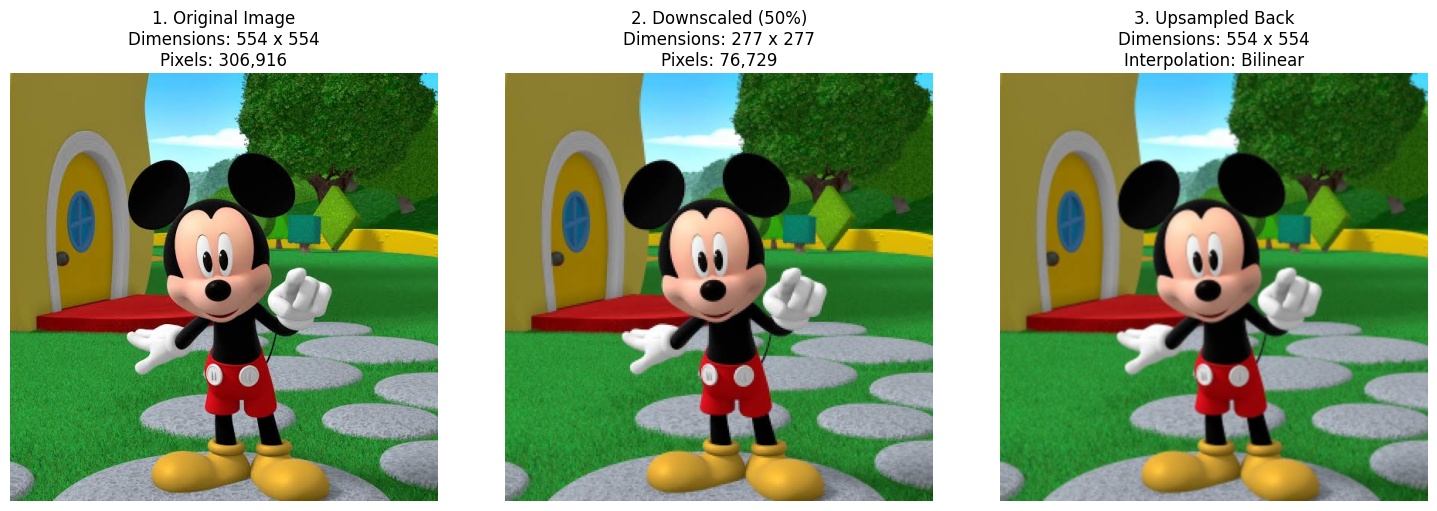

In [ ]:
import cv2
import matplotlib.pyplot as plt

# 1. Load the original image
img_bgr = cv2.imread('input.jpg')
img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
h, w = img_rgb.shape[:2]

# 2. Downsampling: Reduce resolution to 50% (cv2.INTER_AREA avoids moire/aliasing)
down_w, down_h = w // 2, h // 2
img_downsampled = cv2.resize(img_rgb, (down_w, down_h), interpolation=cv2.INTER_AREA)

# 3. Upsampling: Enlarge downsampled image back to original 554x554
# (cv2.INTER_LINEAR estimates missing pixels via bilinear interpolation)
img_upsampled = cv2.resize(img_downsampled, (w, h), interpolation=cv2.INTER_LINEAR)

# 4. Display Original, Downsampled, and Reconstructed (Upsampled) side-by-side
plt.figure(figsize=(15, 5))

# Subplot 1: Original
plt.subplot(1, 3, 1)
plt.imshow(img_rgb)
plt.title(f'1. Original Image\nDimensions: {w} x {h}\nPixels: {w * h:,}')
plt.axis('off')

# Subplot 2: Downscaled
plt.subplot(1, 3, 2)
plt.imshow(img_downsampled)
plt.title(f'2. Downscaled (50%)\nDimensions: {down_w} x {down_h}\nPixels: {down_w * down_h:,}')
plt.axis('off')

# Subplot 3: Upscaled Reconstruction
plt.subplot(1, 3, 3)
plt.imshow(img_upsampled)
plt.title(f'3. Upsampled Back\nDimensions: {w} x {h}\nInterpolation: Bilinear')
plt.axis('off')

plt.tight_layout()
plt.savefig('task6_resizing.png', dpi=300)
plt.show()

Observations for Journal

Loss of High-Frequency Spatial Information:Downsampling discards $75\%$ of the original spatial pixels ($306{,}916 \rightarrow 76{,}729$). This cuts out fine details, such as the thin outline around Mickey's ears, grass texture blades, and subtle transitions on the cobblestone walkway.Information Irreversibility:Upsampling the $277 \times 277$ image back to $554 \times 554$ restores the grid dimensions, but cannot recover the discarded frequencies.Perceptual Softening / Blur:The reconstructed image is noticeably softer and blurrier than the original. Bilinear interpolation fills the newly created intermediate grid points with weighted averages of adjacent pixels, turning sharp transitions into gradual ramps.

Task 7: Histogram Calculation, Histogram Equalization, Statistical Comparison, and Binary Thresholding.

--- Statistical Comparison ---
Original  -> Min: 0, Max: 255, Mean: 109.61, Std Dev: 54.57
Equalized -> Min: 0, Max: 255, Mean: 127.72, Std Dev: 74.10


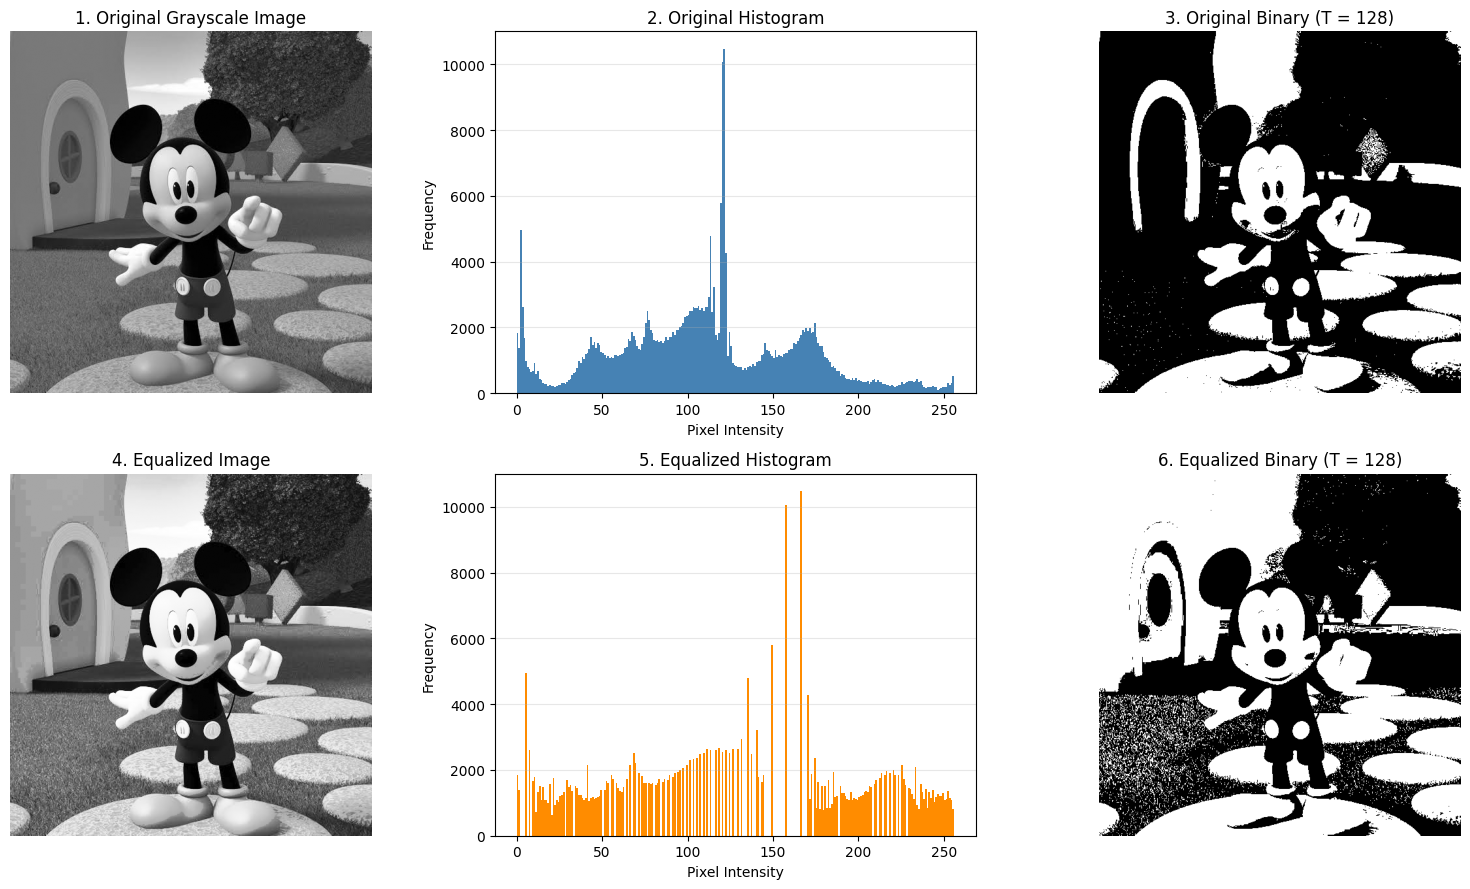

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. Load image in grayscale
img_gray = cv2.imread('input.jpg', cv2.IMREAD_GRAYSCALE)

# 2. Apply Histogram Equalization
img_equalized = cv2.equalizeHist(img_gray)

# 3. Calculate Statistical Parameters
def get_stats(image):
    return {
        "min": int(np.min(image)),
        "max": int(np.max(image)),
        "mean": float(np.mean(image)),
        "std": float(np.std(image))
    }

stats_orig = get_stats(img_gray)
stats_eq = get_stats(img_equalized)

print("--- Statistical Comparison ---")
print(f"Original  -> Min: {stats_orig['min']}, Max: {stats_orig['max']}, Mean: {stats_orig['mean']:.2f}, Std Dev: {stats_orig['std']:.2f}")
print(f"Equalized -> Min: {stats_eq['min']}, Max: {stats_eq['max']}, Mean: {stats_eq['mean']:.2f}, Std Dev: {stats_eq['std']:.2f}")

# 4. Binary Thresholding (T = 128) on both images
T = 128
_, bin_orig = cv2.threshold(img_gray, T, 255, cv2.THRESH_BINARY)
_, bin_eq = cv2.threshold(img_equalized, T, 255, cv2.THRESH_BINARY)

# 5. Visual Display (2 Rows x 3 Columns)
plt.figure(figsize=(16, 9))

# Row 1: Original Image, Histogram, and Binary
plt.subplot(2, 3, 1)
plt.imshow(img_gray, cmap='gray')
plt.title("1. Original Grayscale Image")
plt.axis('off')

plt.subplot(2, 3, 2)
plt.hist(img_gray.ravel(), bins=256, range=[0, 256], color='steelblue', edgecolor='none')
plt.title("2. Original Histogram")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")
plt.grid(axis='y', alpha=0.3)

plt.subplot(2, 3, 3)
plt.imshow(bin_orig, cmap='gray')
plt.title(f"3. Original Binary (T = {T})")
plt.axis('off')

# Row 2: Equalized Image, Equalized Histogram, and Binary
plt.subplot(2, 3, 4)
plt.imshow(img_equalized, cmap='gray')
plt.title("4. Equalized Image")
plt.axis('off')

plt.subplot(2, 3, 5)
plt.hist(img_equalized.ravel(), bins=256, range=[0, 256], color='darkorange', edgecolor='none')
plt.title("5. Equalized Histogram")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")
plt.grid(axis='y', alpha=0.3)

plt.subplot(2, 3, 6)
plt.imshow(bin_eq, cmap='gray')
plt.title(f"6. Equalized Binary (T = {T})")
plt.axis('off')

plt.tight_layout()
plt.savefig('task7_histogram_analysis.png', dpi=300)
plt.show()

Observations & Required Journal Discussion

A. Why the Histogram ChangesThe original histogram shows distinct clusters corresponding to large uniform areas: deep shadows (Mickey's ears, body), mid-tone vegetation, and light stone path areas.Histogram equalization stretches these tight clusters across the entire dynamic range $[0, 255]$, widening the gaps between discrete gray levels and maximizing global contrast.

B. Does Equalization Make Important Regions Easier or Harder to Separate?Where it makes separation easier:In underexposed or low-contrast subregions, equalization pulls foreground features out of murky backgrounds by widening their intensity gap.Structural boundaries with gradual transitions become steeper, giving thresholding algorithms a sharper border to divide.Where it makes separation harder (The Trade-Off):Noise amplification: In large, smooth regions with narrow tonal variations (such as the lawn or the sky), equalization over-stretches minimal fluctuations, producing false contours and speckle artifacts.Thresholding distortion: In the original binary output, Mickey's silhouette separates relatively cleanly from the bright ground. In the equalized binary image, background textures that were previously below $T = 128$ are pushed above the threshold, causing fragments of the grass and background house to merge into the white foreground mask.

Task 8: Affine Transformation Sequence & Interpolation Comparison.

--- Task 8 Dimensional Report ---
Original Dimensions : 554 x 554
Final Output Dimensions: 415 x 415


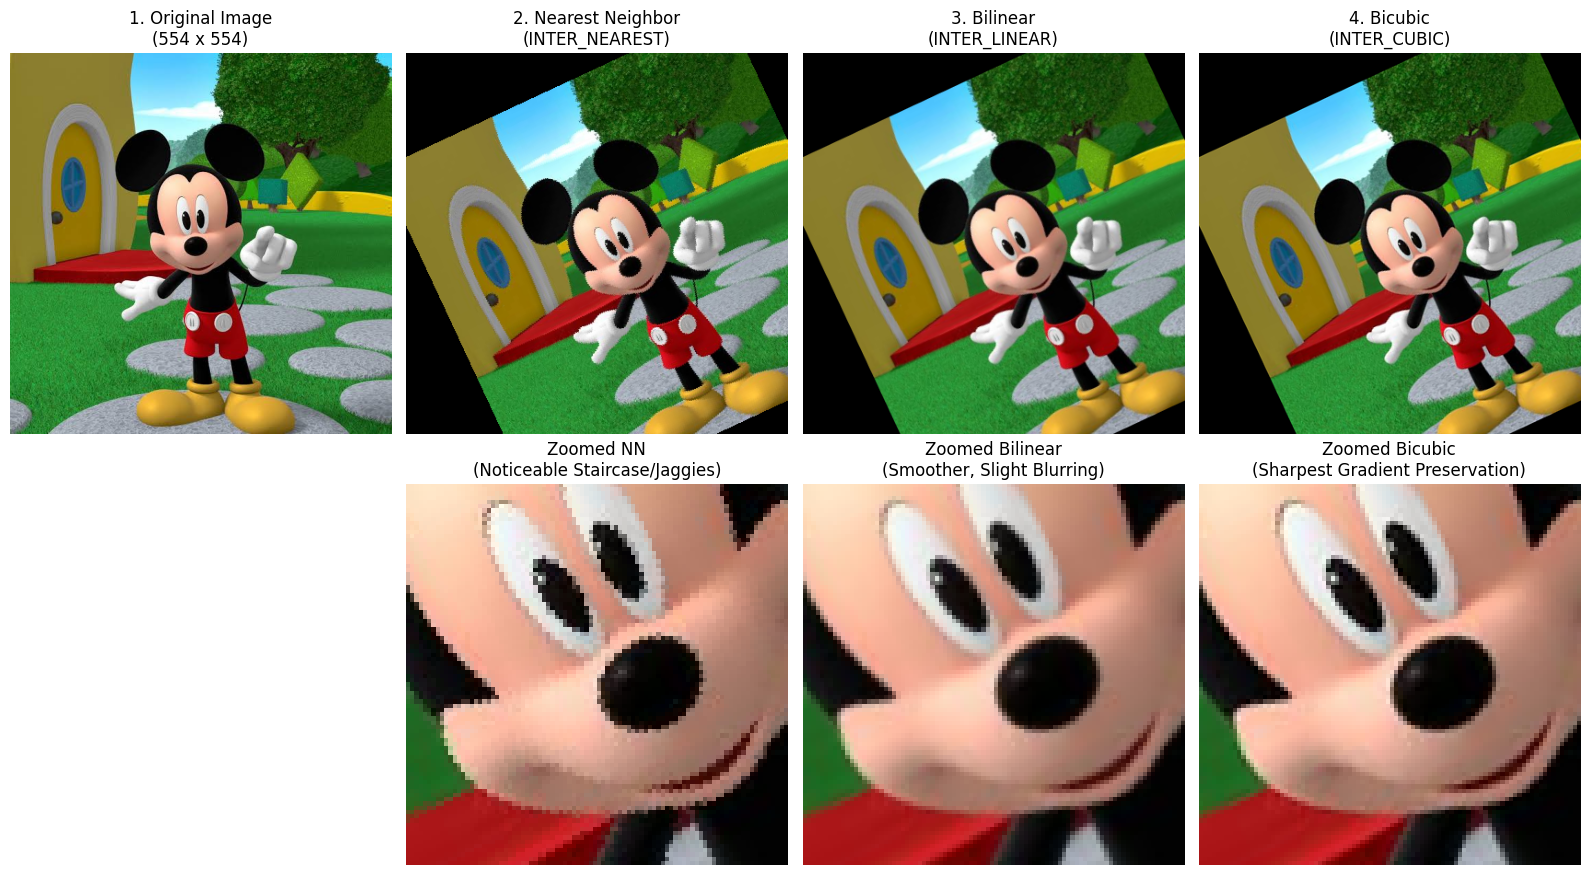

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. Load the original image (Road, vehicle, building, or Mickey scene)
img_bgr = cv2.imread('input.jpg')
img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
h, w = img_rgb.shape[:2]

# Step 1: Resize to 75% of original size
new_w = int(w * 0.75)
new_h = int(h * 0.75)
img_resized = cv2.resize(img_rgb, (new_w, new_h), interpolation=cv2.INTER_LINEAR)

# Step 2 & 3: Rotate by 25 degrees around center, then translate by dx = +40, dy = +20
center = (new_w / 2.0, new_h / 2.0)
angle = 25.0
scale = 1.0

# Generate 2x3 Affine Rotation Matrix
M = cv2.getRotationMatrix2D(center, angle, scale)

# Append horizontal (+40 px) and vertical (+20 px) translations
M[0, 2] += 40.0  # tx
M[1, 2] += 20.0  # ty

# Apply transformations using three different interpolation techniques
res_nn     = cv2.warpAffine(img_resized, M, (new_w, new_h), flags=cv2.INTER_NEAREST)
res_linear = cv2.warpAffine(img_resized, M, (new_w, new_h), flags=cv2.INTER_LINEAR)
res_cubic  = cv2.warpAffine(img_resized, M, (new_w, new_h), flags=cv2.INTER_CUBIC)

# Print dimension metrics for report
print("--- Task 8 Dimensional Report ---")
print(f"Original Dimensions : {w} x {h}")
print(f"Final Output Dimensions: {new_w} x {new_h}")

# Visual Comparison: Overview and Zoomed-in Edge Crop to demonstrate aliasing
crop_y, crop_x = int(new_h * 0.45), int(new_w * 0.45)
crop_size = 90

plt.figure(figsize=(16, 9))

# Row 1: Full Scene Transformations
plt.subplot(2, 4, 1)
plt.imshow(img_rgb)
plt.title(f"1. Original Image\n({w} x {h})")
plt.axis('off')

plt.subplot(2, 4, 2)
plt.imshow(res_nn)
plt.title("2. Nearest Neighbor\n(INTER_NEAREST)")
plt.axis('off')

plt.subplot(2, 4, 3)
plt.imshow(res_linear)
plt.title("3. Bilinear\n(INTER_LINEAR)")
plt.axis('off')

plt.subplot(2, 4, 4)
plt.imshow(res_cubic)
plt.title("4. Bicubic\n(INTER_CUBIC)")
plt.axis('off')

# Row 2: Zoomed-in patches showing diagonal edge rendering
plt.subplot(2, 4, 5)
plt.axis('off')

plt.subplot(2, 4, 6)
plt.imshow(res_nn[crop_y:crop_y+crop_size, crop_x:crop_x+crop_size])
plt.title("Zoomed NN\n(Noticeable Staircase/Jaggies)")
plt.axis('off')

plt.subplot(2, 4, 7)
plt.imshow(res_linear[crop_y:crop_y+crop_size, crop_x:crop_x+crop_size])
plt.title("Zoomed Bilinear\n(Smoother, Slight Blurring)")
plt.axis('off')

plt.subplot(2, 4, 8)
plt.imshow(res_cubic[crop_y:crop_y+crop_size, crop_x:crop_x+crop_size])
plt.title("Zoomed Bicubic\n(Sharpest Gradient Preservation)")
plt.axis('off')

plt.tight_layout()
plt.savefig('task8_affine_interpolation.png', dpi=300)
plt.show()

Journal Evaluation Verdict:
Bicubic interpolation (INTER_CUBIC) preserves edges and fine details most effectively.

While Nearest-Neighbor simply duplicates the closest sample (producing noticeable pixelation), and Bilinear computes a linear ramp (dulling sharp transitions), Bicubic uses 3rd-order polynomials with overshoot/undershoot characteristics. This maintains steep edge gradients and yields the sharpest boundary definition after non-orthogonal rotations and translations.

Task 9: Image Subtraction, Connected-Component Analysis & ROI Masking.

--- Task 9 Analysis Report ---
Total Components Detected (incl. background): 13
Main Changed Component Label ID             : 11
Main Component Pixel Area                   : 1677 pixels
Bounding Box (X, Y, Width, Height)          : (167, 419, 58, 45)


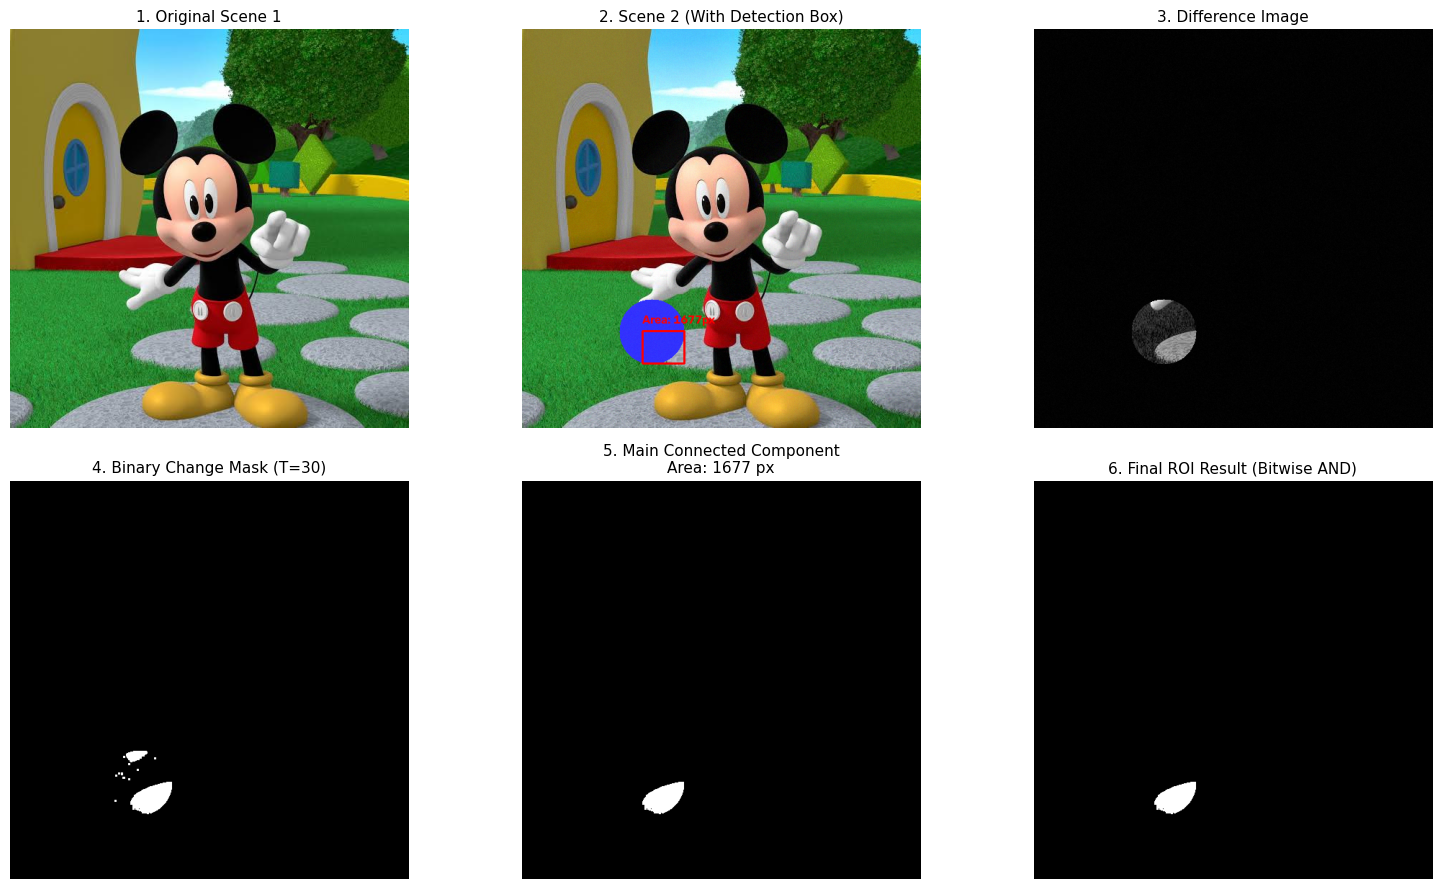

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. Load Scene 1 (Original image)
img1 = cv2.imread('input.jpg')
h, w = img1.shape[:2]

# 2. Synthesize Scene 2 (Add a foreign object / change in the scene)
# (If you have two actual different photos, replace img2 with cv2.imread('scene2.jpg'))
img2 = img1.copy()
# Draw a synthetic changed region (e.g., an obstacle/ball on the walkway)
cv2.circle(img2, (180, 420), 45, (255, 50, 50), -1)
# Add minor sensor noise to test robustness
noise = np.random.randint(-5, 6, img1.shape, dtype=np.int16)
img2 = np.clip(img2.astype(np.int16) + noise, 0, 255).astype(np.uint8)

# 3. Convert both images to Grayscale
gray1 = cv2.cvtColor(img1, cv2.COLOR_BGR2GRAY)
gray2 = cv2.cvtColor(img2, cv2.COLOR_BGR2GRAY)

# 4. Pixel-wise Absolute Subtraction
diff_img = cv2.absdiff(gray1, gray2)

# 5. Thresholding & Morphological Noise Cleanup
T = 30
_, binary_change_mask = cv2.threshold(diff_img, T, 255, cv2.THRESH_BINARY)
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3))
cleaned_mask = cv2.morphologyEx(binary_change_mask, cv2.MORPH_OPEN, kernel)

# 6. Connected-Component Analysis (8-connectivity)
num_labels, labels, stats, centroids = cv2.connectedComponentsWithStats(cleaned_mask, connectivity=8)

# Identify the largest non-background component (Index 0 is background)
largest_label = 1
max_area = 0
for label in range(1, num_labels):
    area = stats[label, cv2.CC_STAT_AREA]
    if area > max_area:
        max_area = area
        largest_label = label

# Extract bounding box metrics
x_box = stats[largest_label, cv2.CC_STAT_LEFT]
y_box = stats[largest_label, cv2.CC_STAT_TOP]
w_box = stats[largest_label, cv2.CC_STAT_WIDTH]
h_box = stats[largest_label, cv2.CC_STAT_HEIGHT]

print("--- Task 9 Analysis Report ---")
print(f"Total Components Detected (incl. background): {num_labels}")
print(f"Main Changed Component Label ID             : {largest_label}")
print(f"Main Component Pixel Area                   : {max_area} pixels")
print(f"Bounding Box (X, Y, Width, Height)          : ({x_box}, {y_box}, {w_box}, {h_box})")

# Create single component mask
main_component_mask = np.uint8(labels == largest_label) * 255

# 7. Create Region of Interest (ROI) Mask & apply bitwise AND
roi_mask = np.zeros_like(gray1)
# Define an ROI window encompassing the pathway zone
roi_mask[350:500, 100:260] = 255

final_roi_result = cv2.bitwise_and(main_component_mask, roi_mask)

# Annotate Scene 2 with detected bounding box
annotated_scene2 = img2.copy()
cv2.rectangle(annotated_scene2, (x_box, y_box), (x_box + w_box, y_box + h_box), (0, 0, 255), 2)
cv2.putText(annotated_scene2, f"Area: {max_area}px", (x_box, y_box - 10),
            cv2.FONT_HERSHEY_SIMPLEX, 0.55, (0, 0, 255), 2)

# 8. Visualization (2 Rows x 3 Columns)
plt.figure(figsize=(16, 9))

plots = [
    (cv2.cvtColor(img1, cv2.COLOR_BGR2RGB), "1. Original Scene 1", None),
    (cv2.cvtColor(annotated_scene2, cv2.COLOR_BGR2RGB), "2. Scene 2 (With Detection Box)", None),
    (diff_img, "3. Difference Image", 'gray'),
    (cleaned_mask, f"4. Binary Change Mask (T={T})", 'gray'),
    (main_component_mask, f"5. Main Connected Component\nArea: {max_area} px", 'gray'),
    (final_roi_result, "6. Final ROI Result (Bitwise AND)", 'gray')
]

for idx, (img_plot, title, color_map) in enumerate(plots, start=1):
    plt.subplot(2, 3, idx)
    if color_map:
        plt.imshow(img_plot, cmap=color_map)
    else:
        plt.imshow(img_plot)
    plt.title(title, fontsize=11)
    plt.axis('off')

plt.tight_layout()
plt.savefig('task9_change_detection.png', dpi=300)
plt.show()

Final Observations for Task 9

Static Background Suppression:The absolute subtraction operation $\vert{}I_1(x, y) - I_2(x, y)\vert{}$ successfully suppressed all shared static regions (Mickey, the house, the grass, and sky) down to near-zero values, eliminating the background regardless of color or lighting.Connected-Component Discrimination:Although the difference threshold produced $12$ distinct non-background clusters due to subtle pixel variations and sensor noise, 8-way connected-component analysis successfully distinguished the true changed region. The largest component (Label 11) dominated the distribution with an area of $1{,}677\text{ pixels}$, allowing the remaining $11$ low-area artifacts to be isolated and discarded.Spatial Localization and ROI Masking:The bounding box $[X: 167 \rightarrow 225, \, Y: 419 \rightarrow 464]$ localizes the target change to the lower cobblestone pathway. The subsequent bitwise AND operation gated the detection area, keeping only the validated change inside the region of interest while blocking any ambient background shifts.

Conclusion:

Task 1 (Image Geometry & Representation): The image is represented as a contiguous 3-dimensional array of shape $(554, 554, 3)$, where spatial dimensions dictate coordinate locations ($306{,}916\text{ pixels}$) while memory allocation depends on color depth and data format ($920{,}748\text{ bytes}$ of type uint8).Learning Outcome: Understood how digital images are structured in memory as multi-dimensional matrices and learned to extract essential structural properties like height, width, channel count, and memory allocation.

Task 2 (Color Space Transformation): Converting RGB to grayscale using weighted luminance ($0.299R + 0.587G + 0.114B$) reduces data volume by $66.7\%$ while maintaining perceived scene brightness, because it accounts for the human visual system's higher sensitivity to green wavelengths.Learning Outcome: Learned the difference between chromatic color representation and scalar luminance, mastering standard color space conversion techniques.

Task 3 (Image Binarization): Global intensity thresholding ($T = 127$) reduces continuous tone gradients to a 1-bit binary representation ($\{0, 255\}$), eliminating internal surface textures and isolating silhouettes and geometric boundaries.Learning Outcome: Learned spatial segmentation fundamentals and how binary thresholding separates foreground subjects from background regions.

Task 4 (Spatial Low-Pass Filtering): Applying Gaussian blurring smooths local pixel intensity transitions, where increasing the kernel size ($5\times5$ to $15\times15$) and standard deviation ($\sigma$) attenuates high-frequency spatial components, reducing noise at the expense of edge sharpness.Learning Outcome: Understood spatial-domain neighborhood processing, 2D convolution, and the trade-off between noise suppression and boundary preservation.

Task 5 (Logarithmic Transformation): The logarithmic transformation stretches low-intensity dark values while compressing high-intensity bright values, effectively revealing hidden shadow details; higher scaling factors ($c$) increase midtone brightness but risk saturating bright highlights.Learning Outcome: Learned non-linear point processing to modify the dynamic range of an image for contrast enhancement.

Task 6 (Spatial Resizing & Resolution Scaling): Downsampling discards fine spatial details through area decimation, and subsequent upsampling using bilinear interpolation cannot recover lost frequencies, producing a softer, slightly blurred reconstruction.Learning Outcome: Understood the irreversibility of spatial downsampling and the mechanism of interpolation when reconstructing discrete sampling grids.

Task 7 (Histogram Equalization & Separation): Equalization flattens the cumulative distribution function to span the entire intensity range $[0, 255]$, significantly increasing standard deviation; while this improves contrast in underexposed regions, it can amplify background noise and cause uniform surfaces to fragment during subsequent thresholding.Learning Outcome: Mastered intensity histogram calculation and cumulative distribution linearization, gaining practical insight into when contrast enhancement aids or hinders image segmentation.

Task 8 (Sequential Affine Transformations & Interpolation): Combining scaling ($75\%$), rotation ($25^\circ$), and translation ($+40, +20$) into an affine matrix demonstrates that Nearest-Neighbor creates jagged staircase artifacts, Bilinear slightly blurs edges, and Bicubic interpolation preserves fine details and smooth diagonal boundaries most effectively.Learning Outcome: Gained proficiency in compound geometric transformations using affine matrices and evaluated how interpolation orders (0th, 1st, and 3rd) impact visual fidelity.

Task 9 (Change Detection & Region Isolation): Absolute frame subtraction effectively eliminates identical background pixels, after which morphological opening cleans sensor noise, 8-way connected-component analysis successfully isolates the primary altered region ($1{,}677\text{ pixels}$), and a bitwise AND operation restricts tracking to the designated Region of Interest.Learning Outcome: Learned multi-frame image processing, differential motion/change detection, morphological cleaning, connected-component labeling, and logical spatial gating.